# Player Detection — Evaluation

This notebook evaluates the YOLO11-based role-aware player detection pipeline across all experiments.
The goal is to measure how accurately the model identifies players by their tactical role
(defense, oline, QB, referee, skill) from a single broadcast camera.

---

## Datasets

| Dataset | Description | Role in experiments |
|---------|-------------|---------------------|
| **Roboflow Football-Presnap-Tracker-1** | Public dataset, American football bounding boxes with role annotations across many stadiums | Trained on by us to produce football-specific weights (Stage 2) |
| **Non-Ravelin games (g1–g7)** | Games from other stadiums, annotated with 5 role classes | Cross-stadium training data (Stages 3a, 3b) |
| **TB2025 / Game 8** | Red Tigers vs Styrian Bears, Ravelin Stadium, 2025 — partially annotated | Same-stadium fine-tuning (Stages 4a, 4b) |
| **TB2026** | Red Tigers vs Styrian Bears, Ravelin Stadium, 2026 — fully annotated, 107 frames | **Held-out test set** throughout all cross-stadium stages; k-fold data for architecture grid |

**Classes:** `defense` · `oline` · `qb` · `ref` · `skill`

---

## Experiment Overview

| Stage | Starting weights | Training data | Description |
|-------|-----------------|--------------|-------------|
| 1 | COCO | — | Baseline: generic object detector, no football knowledge |
| 2 | COCO | Roboflow dataset | Role-aware football detector trained by us on public Roboflow data — different stadiums, no Ravelin footage |
| 3a | COCO | g1–g7 non-Ravelin | Role-aware training from scratch on other stadiums |
| 3b | Stage 2 | g1–g7 non-Ravelin | Role-aware training starting from Stage 2 (Roboflow-trained) weights |
| 4a | Stage 3a | g8 (partial) | Same-stadium fine-tuning from COCO-based model |
| 4b | Stage 3b | g8 (partial) | Same-stadium fine-tuning from Stage 2-based model |

All stages are evaluated on the same fixed **TB2026 test set (107 frames)**.

In [16]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor':  'white',
    'axes.facecolor':    'white',
    'savefig.facecolor': 'white',
})

BASE = Path('.')
CS   = BASE / 'cross_stadium_results'
UB   = BASE / 'upper_bound_results'
OUT  = BASE / 'evaluation_output'
OUT.mkdir(exist_ok=True)

CLASSES = ['defense', 'oline', 'qb', 'ref', 'skill']
STAGES  = ['1', '2', '3a', '3b', '4a', '4b']
STAGE_LABELS = {
    '1':  'Stage 1\nCOCO\nzero-shot',
    '2':  'Stage 2\nRoboflow-\ntrained',
    '3a': 'Stage 3a\nCOCO →\nnon-Ravelin',
    '3b': 'Stage 3b\nStage2 →\nnon-Ravelin',
    '4a': 'Stage 4a\n3a →\nRavelin',
    '4b': 'Stage 4b\n3b →\nRavelin',
}

def load_cs(stage, res):
    return json.loads((CS / f'{stage}_{res}' / 'metrics.json').read_text())

def load_grid():
    return json.loads((UB / 'grid_summary.json').read_text())

print('Paths OK.')

Paths OK.


---
## 1  Architecture & Initialisation Grid

**What:** 5-fold cross-validation over 20 model configurations — 5 YOLO11 sizes (n/s/m/l/x) × 2 resolutions (640/1280px) × 2 starting points (COCO pretrained vs Stage 2 Roboflow-trained weights).  
**Why:** To select the best model backbone before running the main cross-stadium experiment. Avoids guessing architecture and resolution trade-offs.  
**Data:** TB2026 (107 frames) split into 5 folds — TB2026 is used for *both* training and validation here, so results are an upper-bound estimate, not a generalisation measure.

In [17]:
grid = load_grid()
sizes = ['n', 's', 'm', 'l', 'x']
inits = ['coco', 'roboflow']
ress  = [640, 1280]

cols = pd.MultiIndex.from_product([inits, ress], names=['init', 'res'])
df_grid = pd.DataFrame(index=sizes, columns=cols, dtype=float)

for key, val in grid.items():
    parts = key.split('_')
    init  = parts[0]
    size  = parts[1].replace('yolo11', '')
    res   = int(parts[2])
    folds = val.get('folds', [])
    if folds:
        df_grid.loc[size, (init, res)] = np.mean([f['overall']['mAP50'] for f in folds])

print('Average mAP50 across 5 folds (TB2026 k-fold CV):')
display(df_grid.round(3))

init   coco        roboflow       
res    640    1280     640    1280
n     0.630  0.774    0.917  0.973
s     0.917  0.960    0.950  0.984
m     0.952  0.946    0.966  0.985
l     0.944  0.936    0.969  0.984
x     0.920  0.923    0.966  0.983

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
cmap = 'YlGn'
init_titles = {
    'coco':     'Starting point: COCO pretrained',
    'roboflow': 'Starting point: Roboflow-trained',
}

for ax, init in zip(axes, inits):
    data = df_grid[init].values.astype(float)
    im = ax.imshow(data, cmap=cmap, vmin=0.6, vmax=1.0, aspect='auto')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['640px', '1280px'])
    ax.set_yticks(range(len(sizes)))
    ax.set_yticklabels([f'yolo11{s}' for s in sizes])
    ax.set_title(init_titles[init], fontsize=11)
    for i in range(len(sizes)):
        for j in range(2):
            v = data[i, j]
            ax.text(j, i, f'{v:.3f}', ha='center', va='center',
                    fontsize=10, color='black' if v > 0.78 else 'white')

fig.colorbar(im, ax=axes, label='mAP50')
fig.suptitle('Architecture Grid — mAP50 on TB2026 (5-fold CV)', fontsize=13)
plt.tight_layout()
plt.savefig(OUT / 'grid_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Find best
best_val = df_grid.values.astype(float)
idx = np.unravel_index(np.nanargmax(best_val), best_val.shape)
best_size = sizes[idx[0]]
best_init = df_grid.columns[idx[1]][0]
best_res  = df_grid.columns[idx[1]][1]
print(f'Best config: yolo11{best_size} @ {best_res}px, init={best_init}  →  mAP50={best_val[idx]:.3f}')
print('→ yolo11m @ 1280px with Roboflow-trained initialisation selected for all subsequent experiments.')

Best config: yolo11m @ 1280px, init=roboflow  →  mAP50=0.985
→ yolo11m @ 1280px with Roboflow-trained initialisation selected for all subsequent experiments.


---
## 2  Cross-Stadium Progressive Fine-Tuning

**What:** Six training stages with progressively more domain-specific data, all evaluated on the same fixed TB2026 test set. The model backbone is fixed to **yolo11m @ 1280px** throughout (selected above).  
**Why:** To measure how each source of training data contributes to performance — isolating the effect of football-specific pretraining, role annotation from other stadiums, and same-stadium fine-tuning. Answers RQ1 (detection accuracy) and RQ5 (cross-stadium generalisation).  
**Data:**  
- Stage 1: COCO zero-shot — no football knowledge, no role classes  
- Stage 2: Roboflow public data — role-aware, but only other-stadium footage  
- Stages 3a–3b: game1–game7 non-Ravelin games (role-annotated, different stadium)
- Stages 4a–4b: additionally fine-tuned on game8 (same Ravelin stadium, partial annotations)
- Test set: TB2026 (107 frames, never used in training)

In [19]:
rows = []
for stage in STAGES:
    for res in [640, 1280]:
        m  = load_cs(stage, res)
        ov = m['overall']
        rows.append({'Stage': stage, 'Resolution': res,
                     'mAP50': ov['mAP50'], 'mAP50-95': ov['mAP50-95'],
                     'Precision': ov['precision'], 'Recall': ov['recall'],
                     'FPS': ov['fps']})

df_cs = pd.DataFrame(rows)
pivot = df_cs.pivot(index='Stage', columns='Resolution',
                    values=['mAP50', 'mAP50-95', 'Precision', 'Recall', 'FPS'])
pivot = pivot.reindex(STAGES)
print('Cross-stadium results on tb2026 test set (107 frames):')
display(pivot.round(3))

mAP50        mAP50-95        Precision        Recall          FPS  \
Resolution   640    1280     640    1280      640    1280   640    1280  640    
Stage                                                                           
1           0.039  0.028    0.016  0.013     0.041  0.626  0.212  0.136  18.2   
2           0.613  0.741    0.361  0.456     0.683  0.720  0.532  0.648  29.4   
3a          0.832  0.835    0.492  0.517     0.863  0.818  0.730  0.741  28.4   
3b          0.885  0.917    0.541  0.575     0.880  0.894  0.802  0.860  27.7   
4a          0.834  0.714    0.492  0.416     0.869  0.705  0.732  0.622  29.5   
4b          0.862  0.906    0.481  0.557     0.852  0.863  0.758  0.848  28.3   

                  
Resolution  1280  
Stage             
1           24.7  
2           30.8  
3a          29.8  
3b          30.9  
4a          30.0  
4b          30.6

In [20]:
# Baseline comparison table — Stage 1 and Stage 2
baseline_rows = []
for stage, label in [('1', 'Stage 1 — COCO zero-shot'), ('2', 'Stage 2 — Roboflow-trained')]:
    for res in [640, 1280]:
        m = load_cs(stage, res)
        ov = m['overall']
        baseline_rows.append({
            'Stage': label,
            'Resolution': f'{res}px',
            'mAP50': ov['mAP50'],
            'mAP50-95': ov['mAP50-95'],
        })

df_baselines = pd.DataFrame(baseline_rows).set_index(['Stage', 'Resolution'])
print('Baselines on tb2026 test set:')
display(df_baselines.round(3))

mAP50  mAP50-95
Stage                      Resolution                 
Stage 1 — COCO zero-shot   640px       0.039     0.016
                           1280px      0.028     0.013
Stage 2 — Roboflow-trained 640px       0.613     0.361
                           1280px      0.741     0.456

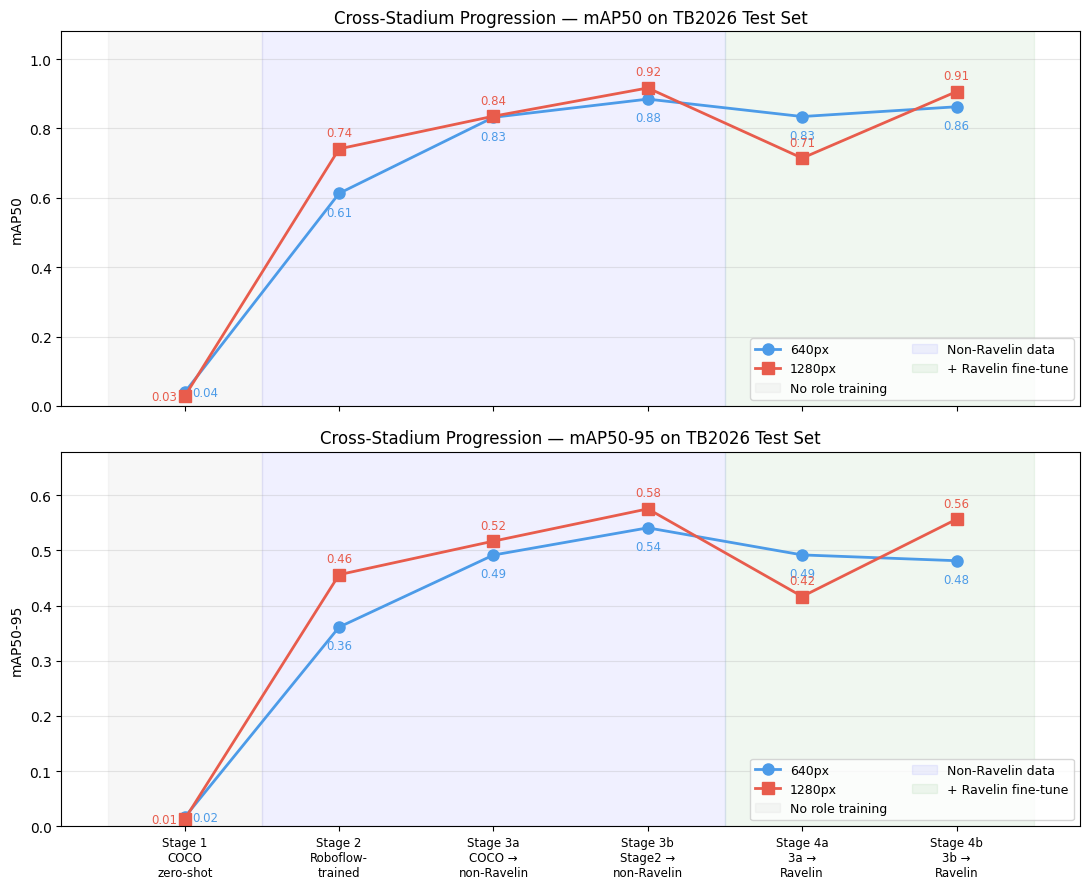

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
x = np.arange(len(STAGES))

offsets    = {640: -16, 1280: 9}
offsets_s1 = {640: (24, 0), 1280: (-24, 0)}

for metric, ax, ylabel, title in [
    ('mAP50',    axes[0], 'mAP50',    'Cross-Stadium Progression — mAP50 on TB2026 Test Set'),
    ('mAP50-95', axes[1], 'mAP50-95', 'Cross-Stadium Progression — mAP50-95 on TB2026 Test Set'),
]:
    for res, color, marker in [(640, '#4C9BE8', 'o'), (1280, '#E85C4C', 's')]:
        sub = df_cs[df_cs['Resolution'] == res].set_index('Stage').reindex(STAGES)
        ax.plot(x, sub[metric], marker=marker, color=color,
                linewidth=2, markersize=8, label=f'{res}px')
        for xi, (stage, row) in zip(x, sub.iterrows()):
            if stage == '1':
                xyt = offsets_s1[res]
                ha  = 'right' if res == 640 else 'left'
                ax.annotate(f"{row[metric]:.2f}", (xi, row[metric]),
                            textcoords='offset points', xytext=xyt,
                            ha=ha, va='center', fontsize=8.5, color=color)
            else:
                ax.annotate(f"{row[metric]:.2f}", (xi, row[metric]),
                            textcoords='offset points', xytext=(0, offsets[res]),
                            ha='center', fontsize=8.5, color=color)

    ax.axvspan(-0.5, 0.5, alpha=0.06, color='grey',  label='No role training')
    ax.axvspan( 0.5, 3.5, alpha=0.06, color='blue',  label='Non-Ravelin data')
    ax.axvspan( 3.5, 5.5, alpha=0.06, color='green', label='+ Ravelin fine-tune')
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(sub[metric].max() * 1.18, 0.1) if metric == 'mAP50-95' else 1.08)
    ax.set_title(title)
    ax.legend(fontsize=9, ncol=2)
    ax.grid(axis='y', alpha=0.3)

axes[1].set_xticks(x)
axes[1].set_xticklabels([STAGE_LABELS[s] for s in STAGES], fontsize=8.5)
plt.tight_layout()
plt.savefig(OUT / 'progression_dual.png', dpi=150, bbox_inches='tight')
plt.show()

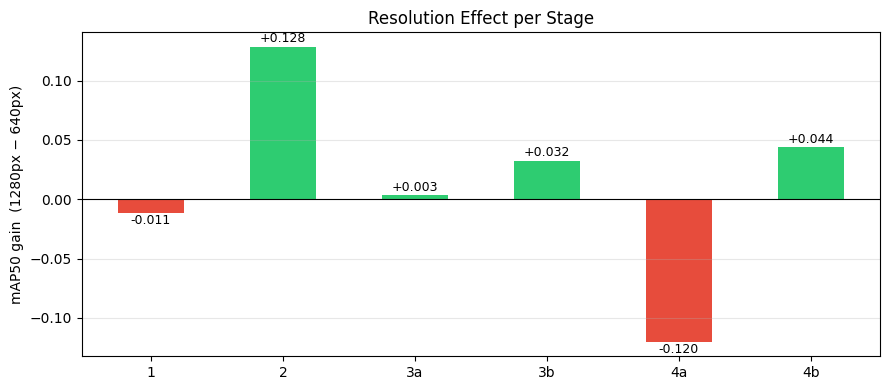

In [22]:
# Resolution delta: does 1280 always help?
fig, ax = plt.subplots(figsize=(9, 4))
delta = [load_cs(s, 1280)['overall']['mAP50'] - load_cs(s, 640)['overall']['mAP50']
         for s in STAGES]
colors = ['#2ecc71' if d >= 0 else '#e74c3c' for d in delta]
ax.bar(STAGES, delta, color=colors, width=0.5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('mAP50 gain  (1280px − 640px)')
ax.set_title('Resolution Effect per Stage')
for i, d in enumerate(delta):
    ax.text(i, d + (0.004 if d >= 0 else -0.01), f'{d:+.3f}', ha='center', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / 'resolution_delta.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3  Per-Class Analysis — Stage 3b @ 1280px

**What:** Per-class breakdown of mAP50, mAP50-95, precision, and recall for the best model, plus a comparison of per-class mAP50 across all stages.  
**Why:** Reveals which player roles are easy or hard to detect, and how each training stage affects individual classes.

In [23]:
best_m = load_cs('3b', 1280)
cls_d  = best_m['per_class']

rows = []
for cls in CLASSES:
    d = cls_d.get(cls, {})
    rows.append({'Class': cls,
                 'mAP50':     d.get('mAP50', None),
                 'mAP50-95':  d.get('mAP50-95', None),
                 'Precision': d.get('precision', None),
                 'Recall':    d.get('recall', None)})
df_cls = pd.DataFrame(rows).set_index('Class')
print('Stage 3b @ 1280px — per-class metrics on TB2026:')
display(df_cls.round(3))

,mAP50,mAP50-95,Precision,Recall
Class,,,,
defense,0.938,0.605,0.896,0.899
oline,0.879,0.496,0.827,0.888
qb,0.961,0.614,0.915,0.916
ref,0.867,0.487,0.916,0.723
skill,0.939,0.676,0.914,0.872


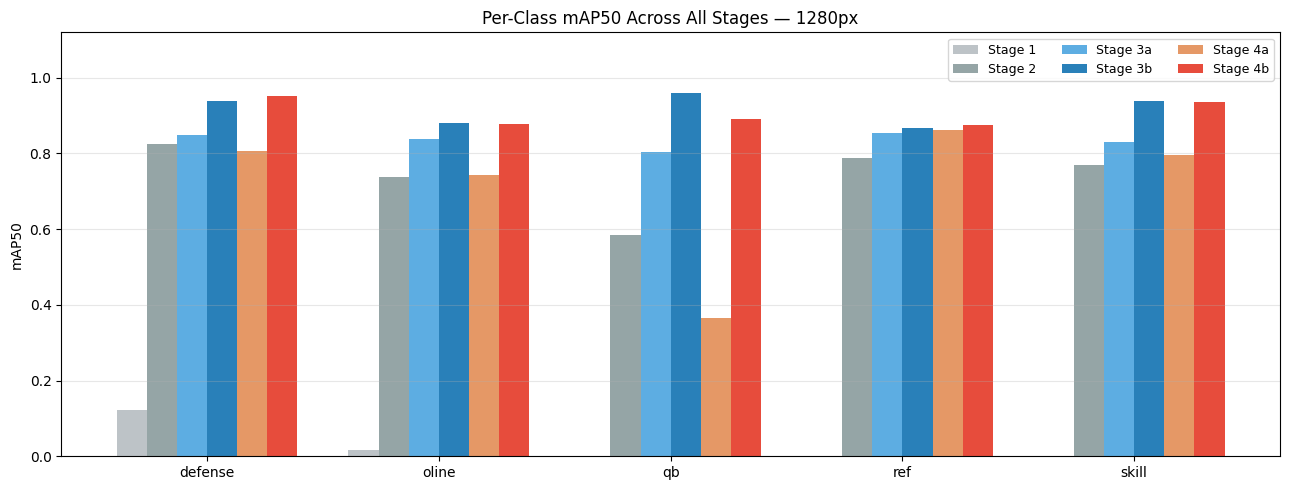

In [24]:
# Per-class mAP50 across all stages @ 1280px — shows which classes improve with more data
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(CLASSES))
n = len(STAGES)
w = 0.13
stage_colors = ['#bdc3c7', '#95a5a6', '#5dade2', '#2980b9', '#e59866', '#e74c3c']

for i, (stage, color) in enumerate(zip(STAGES, stage_colors)):
    m = load_cs(stage, 1280)
    vals = [m['per_class'].get(c, {}).get('mAP50', 0) for c in CLASSES]
    offset = (i - n/2 + 0.5) * w
    ax.bar(x + offset, vals, w, label=f'Stage {stage}', color=color)

ax.set_xticks(x); ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.12); ax.set_ylabel('mAP50')
ax.set_title('Per-Class mAP50 Across All Stages — 1280px')
ax.legend(ncol=3, fontsize=9); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / 'per_class_all_stages.png', dpi=150, bbox_inches='tight')
plt.show()

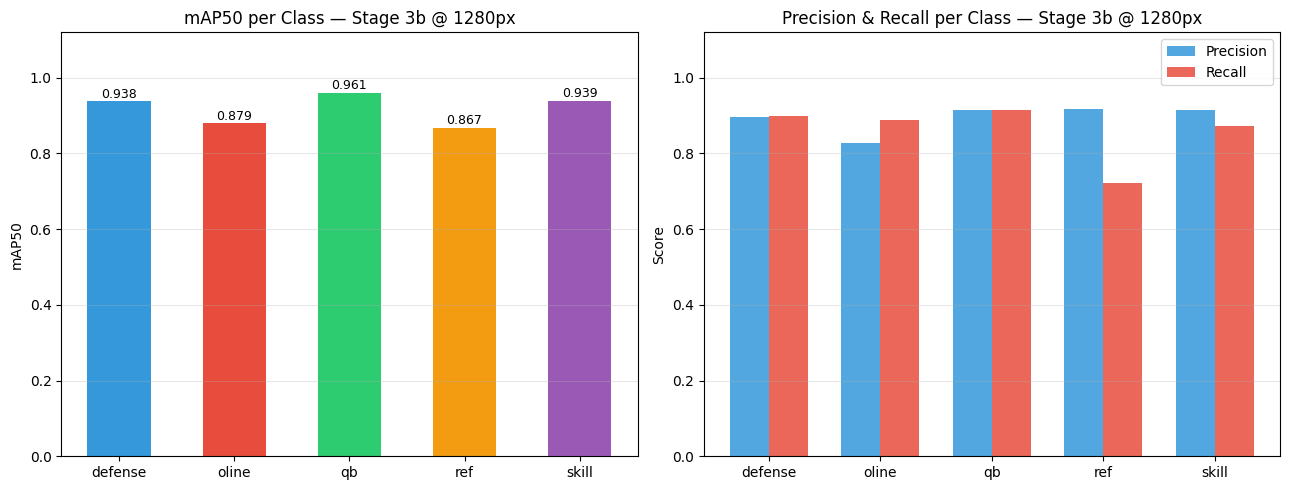

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(CLASSES))
cls_colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']
width = 0.35

# mAP50 per class
ax = axes[0]
vals = [cls_d.get(c, {}).get('mAP50', 0) for c in CLASSES]
bars = ax.bar(x, vals, color=cls_colors, width=0.55)
ax.set_xticks(x); ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.12); ax.set_ylabel('mAP50')
ax.set_title('mAP50 per Class — Stage 3b @ 1280px')
ax.grid(axis='y', alpha=0.3)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)

# Precision vs Recall per class
ax = axes[1]
prec = [cls_d.get(c, {}).get('precision', 0) for c in CLASSES]
rec  = [cls_d.get(c, {}).get('recall', 0)    for c in CLASSES]
ax.bar(x - width/2, prec, width, label='Precision', color='#3498db', alpha=0.85)
ax.bar(x + width/2, rec,  width, label='Recall',    color='#e74c3c', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.12); ax.set_ylabel('Score')
ax.set_title('Precision & Recall per Class — Stage 3b @ 1280px')
ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'per_class_best.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4  Confusion Matrix — Stage 3b @ 1280px

**What:** Confusion matrix between predicted and ground-truth role classes for the best model.  
**Why:** Reveals which roles get confused with each other — important for understanding pipeline errors downstream (e.g. a misclassified oline player would corrupt formation analysis).  
**Data:** TB2026 test set.

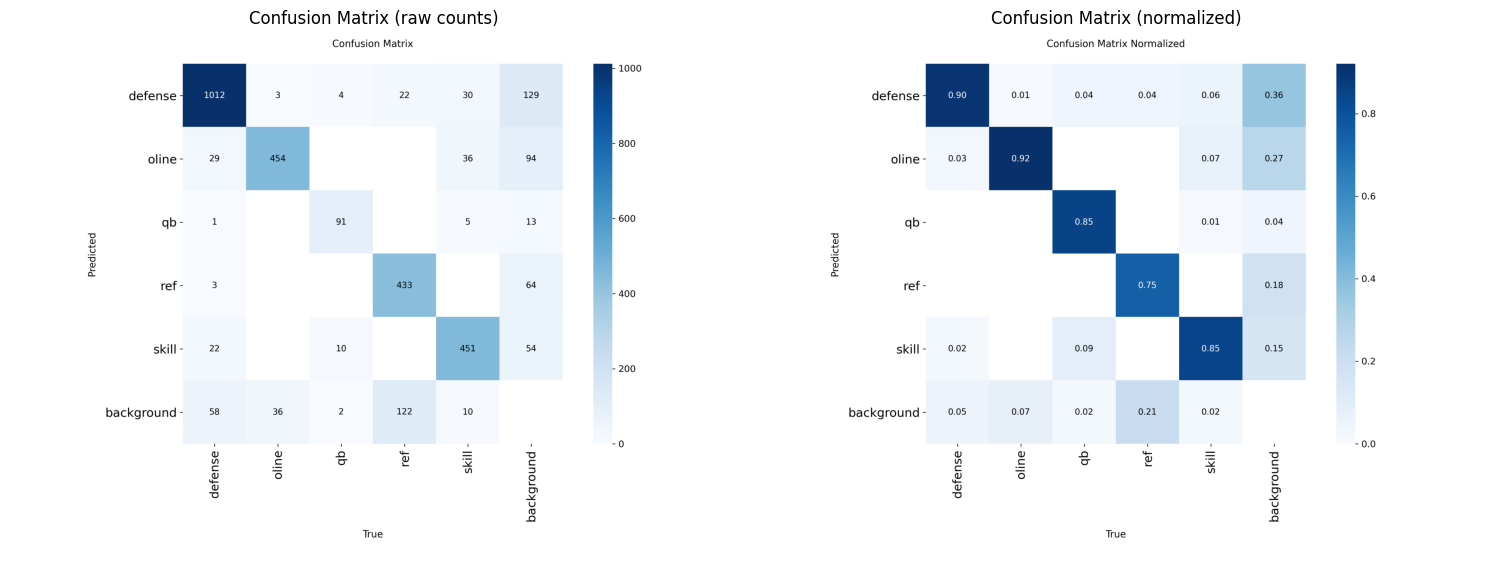

In [15]:
eval_dir = CS / '3b_1280' / 'eval'
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, fname, title in zip(
    axes,
    ['confusion_matrix.png', 'confusion_matrix_normalized.png'],
    ['Confusion Matrix (raw counts)', 'Confusion Matrix (normalized)']
):
    ax.imshow(mpimg.imread(eval_dir / fname))
    ax.axis('off')
    ax.set_title(title, fontsize=12)
plt.tight_layout()
plt.savefig(OUT / 'confusion_matrix_combined.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5  Qualitative Examples — Stage 3b @ 1280px

**What:** Side-by-side ground truth labels vs model predictions on the TB2026 test set.
**Why:** Quantitative metrics alone can miss systematic errors (e.g. correct count but wrong roles). Visual inspection confirms whether detections make tactical sense.

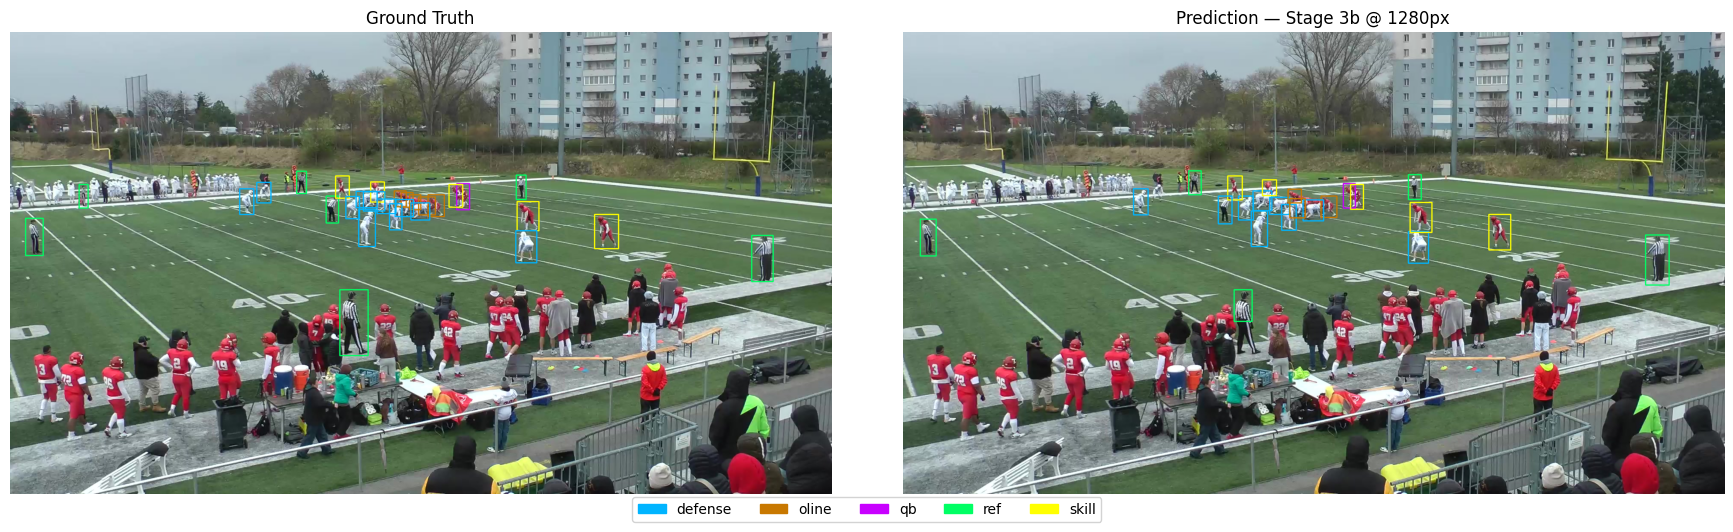

In [12]:
import cv2
import yaml
import random
import matplotlib.patches as mpatches

# ── Config ─────────────────────────────────────────────────────────────────────
TB2026_YAML = Path('/mnt/c/Users/Lukas/Documents/Semester_5/Master_Thesis/Project'
                   '/Data/Players/datasets/cross_stadium/eval_only.yaml')
N_SAMPLES   = 3
SEED        = 472
CONF_THRESH = 0.5
BOX_THICK   = 2

CLASS_COLORS_BGR = {
    'defense': (255, 180,   0),
    'oline':   (0,   120, 200),
    'qb':      (255,   0, 200),
    'ref':     (100, 255,   0),
    'skill':   (0,   255, 255),
}
CLASS_COLORS_RGB = {k: (r/255, g/255, b/255) for k, (b, g, r) in CLASS_COLORS_BGR.items()}

def _draw_box(img, x1, y1, x2, y2, color):
    cv2.rectangle(img, (x1, y1), (x2, y2), color, BOX_THICK)

legend_handles = [
    mpatches.Patch(color=CLASS_COLORS_RGB[cls], label=cls)
    for cls in ['defense', 'oline', 'qb', 'ref', 'skill']
]

# Load model and class names
from ultralytics import YOLO as _YOLO
_model      = _YOLO(str(CS / '3b_1280' / 'train' / 'weights' / 'best.pt'))
class_names = _model.names

# Read test image paths
with open(TB2026_YAML) as f:
    _cfg = yaml.safe_load(f)
_root      = Path(_cfg.get('path', str(TB2026_YAML.parent)))
_test_imgs = sorted((_root / _cfg['test']).glob('*.jpg'))
if not _test_imgs:
    _test_imgs = sorted((_root / _cfg['test']).glob('*.png'))

random.seed(SEED)
samples = [_test_imgs[0], _test_imgs[98], _test_imgs[50]]

for idx, img_path in enumerate(samples):
    img_gt   = cv2.imread(str(img_path))
    img_pred = img_gt.copy()
    h, w     = img_gt.shape[:2]

    # Ground truth
    lbl_path = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    if lbl_path.exists():
        for line in lbl_path.read_text().strip().splitlines():
            cls_id, cx, cy, bw, bh = line.split()
            cx, cy, bw, bh = float(cx), float(cy), float(bw), float(bh)
            x1 = int((cx - bw / 2) * w);  y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w);  y2 = int((cy + bh / 2) * h)
            name = class_names[int(cls_id)]
            _draw_box(img_gt, x1, y1, x2, y2, CLASS_COLORS_BGR.get(name, (128, 128, 128)))

    # Predictions
    results = _model.predict(str(img_path), conf=CONF_THRESH, imgsz=1280, verbose=False)[0]
    if results.boxes is not None:
        for box in results.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            name = class_names[int(box.cls[0])]
            _draw_box(img_pred, x1, y1, x2, y2, CLASS_COLORS_BGR.get(name, (128, 128, 128)))

    # Side-by-side with shared legend below
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    axes[0].imshow(cv2.cvtColor(img_gt,   cv2.COLOR_BGR2RGB))
    axes[0].axis('off'); axes[0].set_title('Ground Truth', fontsize=12)
    axes[1].imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB))
    axes[1].axis('off'); axes[1].set_title('Prediction — Stage 3b @ 1280px', fontsize=12)
    fig.legend(handles=legend_handles, loc='lower center', ncol=5,
               fontsize=10, framealpha=0.85, bbox_to_anchor=(0.5, -0.04))
    plt.tight_layout()
    plt.savefig(OUT / f'qualitative_{idx + 1}.png', dpi=150, bbox_inches='tight')
    plt.show()

---
## 6  Field Position Analysis — Stage 3b @ 1280px

**What:** Detection performance stratified by offensive field position on the TB2026 test set.  
**Why:** Field position affects scene composition — plays backed up near the own endzone are often run-heavy with tight splits, while red-zone plays have crowded formations near the endzone pylons. This analysis checks whether detection quality varies by game situation.  
**Data:** TB2026 metadata (107 plays) linked to test images.  
**Field zones:**
- **Own ≤20:** offense within 20 yards of own endzone (backed up; 53 plays)
- **Mid-field:** offense between own 21 and past midfield, not yet in red zone (49 plays)
- **Red zone (opp ≤20):** offense within 20 yards of opponent's endzone (5 plays — limited sample)

Note: `YARD_LN` is signed from Ravelin's perspective (positive = own half, negative = opponent's half). The red-zone plays are all situations where the opponent's offense is in Ravelin's red zone (Ravelin on defense).

In [13]:
import cv2 as _cv2
from collections import defaultdict
from pathlib import Path as _Path

META_CSV   = _Path('/mnt/c/Users/Lukas/Documents/Semester_5/Master_Thesis/Project'
                   '/Data/metadata/tb2026_dataset_metadata.csv')
IMG_DIR    = _Path('/mnt/c/Users/Lukas/Documents/Semester_5/Master_Thesis/Project'
                   '/Data/Players/datasets/cross_stadium/test/images')
LBL_DIR    = _Path('/mnt/c/Users/Lukas/Documents/Semester_5/Master_Thesis/Project'
                   '/Data/Players/datasets/cross_stadium/test/labels')

meta = pd.read_csv(META_CSV)
meta['play_num'] = meta['clip'].str.extract(r'clip_(\d+)').astype(int)

# Field zone categorisation
# YARD_LN: positive = Ravelin's half, negative = past midfield into opponent territory
def _zone(row):
    yl, odk = row['YARD_LN'], row['ODK']
    if odk == 'O':                          # Ravelin on offense
        if yl <= 20:   return 'own ≤20'
        if yl <= -30:  return 'red zone'
        return 'mid-field'
    else:                                   # opponent on offense
        if yl <= -30:  return 'own ≤20'    # opponent backed up
        if yl >= 30:   return 'red zone'   # opponent in Ravelin's red zone
        return 'mid-field'

meta['zone'] = meta.apply(_zone, axis=1)

# Map play_num → image/label paths
meta['img_path'] = meta['play_num'].apply(lambda n: IMG_DIR / f'frame_{n:03d}.jpg')
meta['lbl_path'] = meta['play_num'].apply(lambda n: LBL_DIR / f'frame_{n:03d}.txt')

# ── Per-image TP/FP/FN at IoU ≥ 0.5 ──────────────────────────────────────────
IOU_THRESH = 0.5
CONF       = 0.25   # same default as YOLO val

# Load model (reuse if already loaded)
try:
    _fp_model
except NameError:
    from ultralytics import YOLO as _YOLO
    _fp_model = _YOLO(str(CS / '3b_1280' / 'train' / 'weights' / 'best.pt'))
    _fp_names = _fp_model.names   # {0: 'defense', 1: 'oline', ...}

def _iou(b1, b2):
    xi1, yi1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    xi2, yi2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, xi2-xi1) * max(0, yi2-yi1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter) if (a1+a2-inter) > 0 else 0

def _eval_img(img_path, lbl_path):
    img = _cv2.imread(str(img_path))
    if img is None:
        return {}
    h, w = img.shape[:2]

    gt = []   # (cls_id, x1, y1, x2, y2)
    if lbl_path.exists():
        for ln in lbl_path.read_text().strip().splitlines():
            if not ln.strip(): continue
            c, cx, cy, bw, bh = ln.split()
            cx,cy,bw,bh = float(cx),float(cy),float(bw),float(bh)
            gt.append((int(c),
                       (cx-bw/2)*w, (cy-bh/2)*h,
                       (cx+bw/2)*w, (cy+bh/2)*h))

    res = _fp_model.predict(str(img_path), conf=CONF, imgsz=1280, verbose=False)[0]
    preds = []
    if res.boxes is not None:
        for box in res.boxes:
            c = int(box.cls[0])
            x1,y1,x2,y2 = box.xyxy[0].tolist()
            preds.append((c, x1, y1, x2, y2))

    stats = {c: {'tp':0,'fp':0,'fn':0} for c in _fp_names}
    matched = set()
    for (pc, *pb) in preds:
        best_iou, best_gi = 0, -1
        for gi, (gc, *gb) in enumerate(gt):
            if gc == pc and gi not in matched:
                iou = _iou(pb, gb)
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
        if best_iou >= IOU_THRESH:
            stats[pc]['tp'] += 1
            matched.add(best_gi)
        else:
            stats[pc]['fp'] += 1
    for gi, (gc, *_) in enumerate(gt):
        if gi not in matched:
            stats[gc]['fn'] += 1

    return stats

# Run evaluation over all test images
print('Running per-image evaluation for field position analysis...')
zone_agg = defaultdict(lambda: defaultdict(lambda: {'tp':0,'fp':0,'fn':0}))

for _, row in meta.iterrows():
    zone  = row['zone']
    stats = _eval_img(row['img_path'], row['lbl_path'])
    for cls_id, s in stats.items():
        cls_name = _fp_names[cls_id]
        for k in ('tp','fp','fn'):
            zone_agg[zone][cls_name][k] += s[k]

# Build summary table
ZONES = ['own ≤20', 'mid-field', 'red zone']
zone_counts = meta['zone'].value_counts()

fp_rows = []
for zone in ZONES:
    agg = zone_agg[zone]
    tp  = sum(v['tp'] for v in agg.values())
    fp  = sum(v['fp'] for v in agg.values())
    fn  = sum(v['fn'] for v in agg.values())
    prec = tp / (tp + fp) if (tp+fp) > 0 else float('nan')
    rec  = tp / (tp + fn) if (tp+fn) > 0 else float('nan')
    f1   = 2*prec*rec/(prec+rec) if (prec+rec) > 0 else float('nan')
    fp_rows.append({'Zone': zone,
                    'Plays': zone_counts.get(zone, 0),
                    'Precision': prec, 'Recall': rec, 'F1': f1})

df_fp = pd.DataFrame(fp_rows).set_index('Zone')
print(f'Field position detection metrics — Stage 3b @ 1280px (IoU ≥ {IOU_THRESH}, conf ≥ {CONF}):')
display(df_fp.round(3))

# Per-class recall by zone
fp_cls_rows = []
for zone in ZONES:
    agg = zone_agg[zone]
    row_d = {'Zone': zone}
    for cls in CLASSES:
        s = agg.get(cls, {'tp':0,'fp':0,'fn':0})
        rec = s['tp'] / (s['tp'] + s['fn']) if (s['tp']+s['fn']) > 0 else float('nan')
        row_d[cls] = rec
    fp_cls_rows.append(row_d)

df_fp_cls = pd.DataFrame(fp_cls_rows).set_index('Zone')
print('\nPer-class recall by field zone:')
display(df_fp_cls.round(3))

,defense,oline,qb,ref,skill
Zone,,,,,
own ≤20,0.925,0.963,0.906,0.750,0.886
mid-field,0.897,0.912,0.939,0.791,0.861
red zone,1.000,0.909,1.000,0.741,0.920


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: overall precision / recall / F1 by zone
ax = axes[0]
z_labels = [f'{z}\n(n={zone_counts.get(z,0)})' for z in ZONES]
xz = np.arange(len(ZONES))
w  = 0.25
ax.bar(xz - w, df_fp['Precision'], w, label='Precision', color='#3498db')
ax.bar(xz,     df_fp['Recall'],    w, label='Recall',    color='#e74c3c')
ax.bar(xz + w, df_fp['F1'],        w, label='F1',        color='#2ecc71')
ax.set_xticks(xz); ax.set_xticklabels(z_labels, fontsize=9)
ax.set_ylim(0, 1.12); ax.set_ylabel('Score')
ax.set_title('Overall Detection by Field Zone — Stage 3b @ 1280px')
ax.legend(); ax.grid(axis='y', alpha=0.3)

# Right: per-class recall by zone
ax = axes[1]
n_cls = len(CLASSES)
n_zon = len(ZONES)
w2    = 0.22
zone_colors = ['#5dade2', '#2ecc71', '#e74c3c']
for zi, (zone, color) in enumerate(zip(ZONES, zone_colors)):
    vals   = [df_fp_cls.loc[zone, cls] for cls in CLASSES]
    offset = (zi - n_zon/2 + 0.5) * w2
    ax.bar(np.arange(n_cls) + offset, vals, w2,
           label=f'{zone} (n={zone_counts.get(zone,0)})', color=color)

ax.set_xticks(np.arange(n_cls)); ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.12); ax.set_ylabel('Recall')
ax.set_title('Per-Class Recall by Field Zone — Stage 3b @ 1280px')
ax.legend(fontsize=8.5); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'field_position.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7  Summary

**Best cross-stadium model vs k-fold upper bound.**
The upper bound (Stage 2 in additional experiments) trains and tests on TB2026 via 5-fold CV — not a fair generalisation measure, but sets the ceiling for what is achievable on this data.

In [14]:

ub_folds = [
    json.loads((UB / 'roboflow_yolo11m_1280' / f'fold_{i}_metrics.json').read_text())
    for i in range(1, 6)
]
ub = {k: np.mean([f['overall'][k] for f in ub_folds])
      for k in ['mAP50', 'mAP50-95', 'precision', 'recall']}

best_ov = load_cs('3b', 1280)['overall']

df_summary = pd.DataFrame([
    {'Model': 'Stage 3b @ 1280px  (cross-stadium, Roboflow-trained init)',
     'Train data': 'g1–g7 non-Ravelin',
     'Test data': 'TB2026 (held-out)',
     'mAP50': best_ov['mAP50'], 'mAP50-95': best_ov['mAP50-95'],
     'Precision': best_ov['precision'], 'Recall': best_ov['recall']},
    {'Model': 'Upper bound  (yolo11m@1280 Roboflow-trained init, 5-fold CV)',
     'Train data': 'TB2026 (k-fold)',
     'Test data': 'TB2026 (k-fold)',
     'mAP50': ub['mAP50'], 'mAP50-95': ub['mAP50-95'],
     'Precision': ub['precision'], 'Recall': ub['recall']},
]).set_index('Model')

display(df_summary.round(3))

gap = ub['mAP50'] - best_ov['mAP50']
print(f'\nGap to upper bound: {gap:.3f} mAP50 ({gap*100:.1f} pp)')
print('This gap reflects the cost of not having TB2026 training data.')


Gap to upper bound: 0.068 mAP50 (6.8 pp)
This gap reflects the cost of not having TB2026 training data.
